# Stock Signal Demo

Demonstrates `StockFlexibleSignal` and `StockSignal` for pulling Yahoo Finance data into freqandsee and applying signal processing tools.

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u

from freqandsee.freqandsee import (
    StockFlexibleSignal,
    StockSignal,
    MovingAverageFilter,
    SignalBundle,
)

## Fetch raw stock data as a FlexibleSignal

`StockFlexibleSignal` pulls data from Yahoo Finance. The x-axis contains only trading days (non-uniform spacing).

In [2]:
aapl_raw = StockFlexibleSignal("AAPL", column="Close", period="1y")
aapl_raw

<Axes: title={'center': 'AAPL Close'}, xlabel='Days since 2025-03-31 ($\\mathrm{d}$)', ylabel='Close ($\\mathrm{USD}$)'>

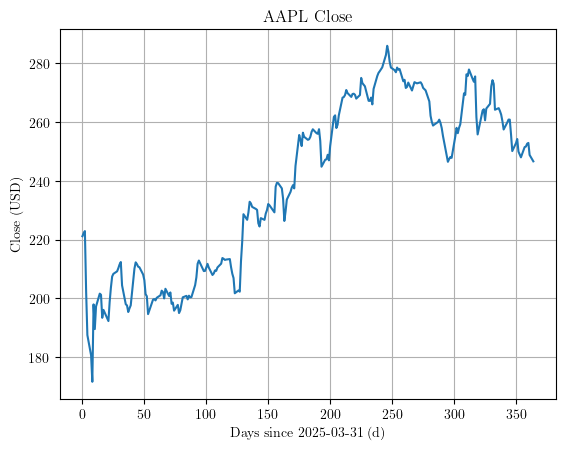

In [3]:
aapl_raw.plot(x_display_unit=u.day, y_display_unit=aapl_raw.y_unit)

## Convert to a uniformly-sampled StockSignal

`StockSignal` interpolates the trading-day data onto a uniform 1-day grid (filling weekends and holidays). This produces a proper `Signal` that supports filtering, PSD, resampling, etc.

In [4]:
aapl = StockSignal("AAPL", column="Close", period="1y")
print(f"Sampling: {aapl.xs} (uniform)")
print(f"Data points: {aapl.n}")
aapl

Sampling: 1.0 d (uniform)
Data points: 364


Signal name: 'AAPL Close (interpolated 1.0 1 / d)' USD(d). n=3.64e+02 sampling points, fs=1.0 1 / d, RMS=2.40e+02 USD.

## Apply moving average filters

Use the `*` operator to filter the stock signal with moving averages of different lengths.

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'AAPL with moving averages'}, xlabel='x(AAPL Close (interpolated 1.0 1 / d) * MA 30-day) ($\\mathrm{d}$)', ylabel='y(AAPL Close (interpolated 1.0 1 / d) * MA 30-day) ($\\mathrm{USD}$)'>)

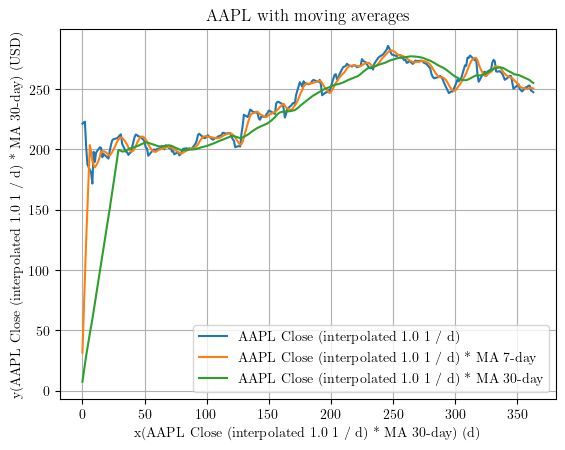

In [5]:
ma7 = aapl * MovingAverageFilter(n=7, name="MA 7-day")
ma30 = aapl * MovingAverageFilter(n=30, name="MA 30-day")

bundle = SignalBundle([aapl, ma7, ma30], name="AAPL with moving averages")
bundle.plot(
    x_display_unit=u.day,
    y_display_unit=aapl.y_unit,
    all_in_one=True,
)

## Power Spectral Density

Compute the PSD to see the frequency content of the stock price signal.

<Axes: title={'center': 'PSD of AAPL Close (interpolated 1.0 1 / d)'}, xlabel='Frequency ($\\mathrm{\\frac{1}{d}}$)', ylabel='PSD(AAPL Close (interpolated 1.0 1 / d)) ($\\mathrm{USD^{2}\\,d}$)'>

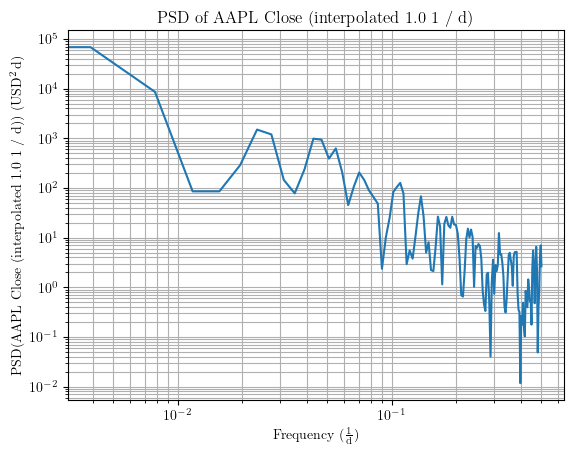

In [6]:
psd = aapl.psd()
psd.plot(x_display_unit=1/u.day, y_display_unit=psd.y_unit)

## Compare multiple tickers

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Tech stocks (6 months)'}, xlabel='Days since 2025-09-30 ($\\mathrm{d}$)', ylabel='Close ($\\mathrm{USD}$)'>)

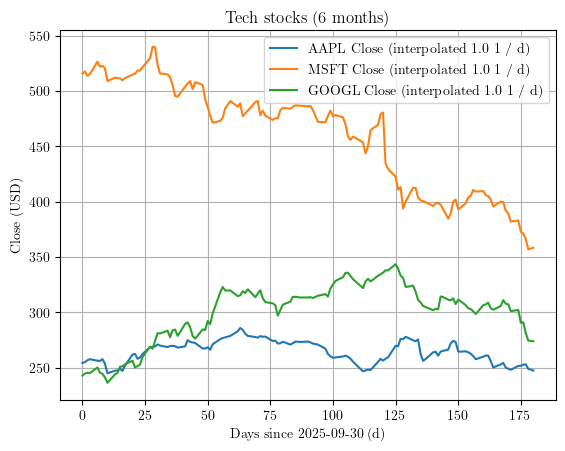

In [7]:
tickers = ["AAPL", "MSFT", "GOOGL"]
signals = [StockSignal(t, column="Close", period="6mo") for t in tickers]
bundle = SignalBundle(signals, name="Tech stocks (6 months)")
bundle.plot(
    x_display_unit=u.day,
    y_display_unit=signals[0].y_unit,
    all_in_one=True,
)

## Accessing the raw Yahoo Finance data

The underlying DataFrame is available via `.history`.

In [8]:
aapl._history.head(10)

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2025-03-31 00:00:00-04:00,216.068270,224.640907,215.291656,221.166061,65299300,0.0,0.0
2025-04-01 00:00:00-04:00,218.856144,222.709345,217.950089,222.221481,36412700,0.0,0.0
2025-04-02 00:00:00-04:00,220.359602,224.212804,220.060901,222.918442,35905900,0.0,0.0
2025-04-03 00:00:00-04:00,204.648036,206.589586,200.376659,202.308243,103419000,0.0,0.0
2025-04-04 00:00:00-04:00,193.048614,199.012626,186.527035,187.562531,125910900,0.0,0.0
2025-04-07 00:00:00-04:00,176.431038,193.307481,173.862232,180.672562,160466300,0.0,0.0
2025-04-08 00:00:00-04:00,185.889798,189.514001,168.475707,171.671768,120859500,0.0,0.0
2025-04-09 00:00:00-04:00,171.203815,199.739448,171.144078,197.987091,184395900,0.0,0.0
2025-04-10 00:00:00-04:00,188.249526,193.934739,182.205860,189.593658,121880000,0.0,0.0


## Volume data

You can also pull volume or OHLC data by changing the `column` parameter.

<Axes: title={'center': 'AAPL Volume (interpolated 1.0 1 / d)'}, xlabel='Days since 2025-09-30 ($\\mathrm{d}$)', ylabel='Volume $\\mathrm{}$'>

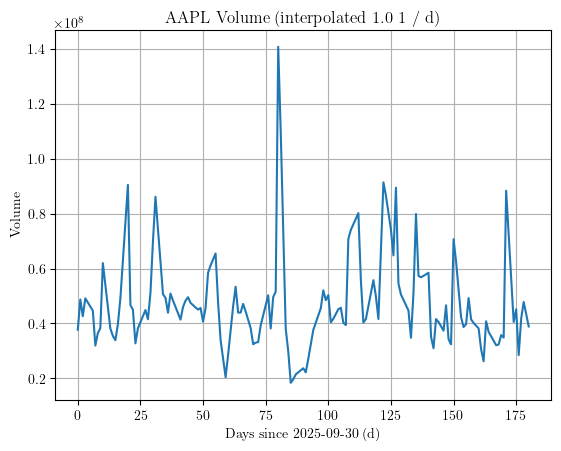

In [9]:
volume = StockSignal("AAPL", column="Volume", period="6mo")
volume.plot(x_display_unit=u.day, y_display_unit=u.dimensionless_unscaled)